<a href="https://colab.research.google.com/github/ejcastrof/Project-NovaRetail/blob/main/S8_Project_NovaRetail.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto 7 - Explorando factores de comportamiento en NovaRetail+


NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**

## Sección 1 - Cargar y explorar el dataset

En esta sección validamos:
- que el dataset cargue correctamente
- tipos de datos
- valores faltantes / rangos generales

Antes de correlacionar, primero entendemos el “terreno”.

In [1]:
# Importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pointbiserialr, chi2_contingency


### Cargar Dataset

In [ ]:
# Cargar el dataset y explorar datos
df = pd.read_csv('/datasets/novaretail_comportamiento_clientes_2024.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.


In [ ]:
# mostrar las primeras 5 filas
df.head()

,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


## Sección 2 - Preparar datos y documentar supuestos

### Exploración y Limpieza

#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
- `edad`
- `nivel_ingreso`
- `visitas_mes`
- `compras_mes`
- `gasto_publicidad_dirigida`
- `satisfaccion`
- `ingreso_anual`

La mayoría de estas variables presentan tipos de datos adecuados.  
La columna `edad` se cargó como `float64` y se convirtió a entero (`int`), porque una edad es un número entero y no tiene valores nulos.



**Variables binarias**  
Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`

Estas variables están correctamente definidas y no requieren transformación adicional.

In [ ]:
# Corregir el tipo de dato
df['edad'] = df['edad'].astype(int)

In [ ]:
# verificar cambios
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  int64  
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(4), int64(5), object(3)
memory usage: 1.4+ MB


#### Explorar variables numéricas

In [ ]:
# Estadísticas descriptivas de variables numéricas
columnas_numericas = ['edad', 'nivel_ingreso', 'visitas_mes', 'compras_mes',
                      'gasto_publicidad_dirigida', 'satisfaccion', 'ingreso_anual']
df[columnas_numericas].describe()

,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,ingreso_anual
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,38.262400,30019.704782,10.029000,1.206467,20.149301,3.603693,36.594180
std,11.492378,9833.166305,3.158189,1.105284,10.880724,0.685300,34.484888
min,18.000000,8000.000000,1.000000,0.000000,0.000000,1.000000,0.000000
25%,30.000000,23127.097500,8.000000,0.000000,12.310000,3.100000,0.000000
50%,38.000000,30023.745000,10.000000,1.000000,19.730000,3.600000,30.705000
75%,46.000000,36768.440000,12.000000,2.000000,27.292500,4.100000,58.220000
max,75.000000,74790.840000,25.000000,8.000000,75.510000,5.000000,244.690000


In [ ]:
# Verificar clientes sin compras e ingreso cero
sin_compras = (df['compras_mes'] == 0).sum()
sin_ingreso = (df['ingreso_anual'] == 0).sum()
ambos = ((df['compras_mes'] == 0) & (df['ingreso_anual'] == 0)).sum()

print("Clientes con 0 compras:", sin_compras)
print("Clientes con ingreso 0:", sin_ingreso)
print("Clientes con ambos:", ambos)
print("Porcentaje del total:", round(ambos / len(df) * 100, 1), "%")

Clientes con 0 compras: 4567
Clientes con ingreso 0: 4567
Clientes con ambos: 4567
Porcentaje del total: 30.4 %


✍️ **Comentario**:

Diagnóstico inicial de variables numéricas

- `edad` — rango de 18 a 75 años, con media 38.3 y mediana 38; sin valores imposibles, distribución centrada.
- `nivel_ingreso` — va de 8,000 a 74,791 con media y mediana casi iguales (≈30,000); es centrada, pero con cola derecha, aunque el máximo queda muy por encima del percentil 75 (36,768), lo que indica unos pocos clientes de ingreso muy alto.
- `visitas_mes` — va de 1 a 25 visitas con mediana 10; el máximo de 25 está bastante por encima del percentil 75 (12), lo que sugiere usuarios muy activos.
- `compras_mes` — va de 0 a 8 con mediana 1; 4,567 clientes (30.4%) no hicieron ninguna compra en el mes (ver verificación en la celda anterior).
- `gasto_publicidad_dirigida` — va de 0 a 75.51 con media 20.1 y mediana 19.7; sin valores negativos y con una distribución bastante simétrica.
- `satisfaccion` — va de 1 a 5, el rango esperado de la escala, con media 3.6; sin valores fuera de rango.
- `ingreso_anual` — va de 0 a 244.69 con media (36.59) mayor que la mediana (30.71) y desviación estándar casi igual a la media; está sesgada a la derecha y 4,567 clientes (30.4%) tienen ingreso 0. Esos mismos 4,567 clientes son los que no hicieron compras, lo que sugiere que no comprar se asocia con no generar ingreso (ver verificación en la celda anterior).

#### Explorar variables binarias

In [ ]:
# Verificar que cada columna tenga únicamente dos valores posibles
columnas_binarias = ['miembro_premium', 'abandono']

for col in columnas_binarias:
    print(col)
    print(df[col].value_counts())
    print()

miembro_premium
0    12911
1     2089
Name: miembro_premium, dtype: int64

abandono
0    12739
1     2261
Name: abandono, dtype: int64



✍️ **Comentario**:

Diagnóstico inicial de variables binarias

- `miembro_premium` — solo contiene los valores 0 y 1; 12,911 clientes (86.1%) no son premium y 2,089 (13.9%) sí lo son, por lo que la clase premium es minoritaria.
- `abandono` — solo contiene los valores 0 y 1; 12,739 clientes (84.9%) permanecen y 2,261 (15.1%) abandonaron la plataforma.

#### Explorar variables categóricas

In [ ]:
# Verificar el número de valores únicos por variable categórica
columnas_categoricas = ['id_cliente', 'tipo_dispositivo', 'region']
print(df[columnas_categoricas].nunique())

id_cliente          15000
tipo_dispositivo        3
region                  4
dtype: int64


In [ ]:
# Explorar variables categóricas y cómo se distribuyen
for col in ['tipo_dispositivo', 'region']:
    print(col)
    print(df[col].value_counts())
    print()
    print(df[col].value_counts(normalize=True).mul(100).round(1))
    print()

tipo_dispositivo
móvil         9818
escritorio    3720
tablet        1462
Name: tipo_dispositivo, dtype: int64

móvil         65.5
escritorio    24.8
tablet         9.7
Name: tipo_dispositivo, dtype: float64

region
norte    4395
oeste    3810
sur      3726
este     3069
Name: region, dtype: int64

norte    29.3
oeste    25.4
sur      24.8
este     20.5
Name: region, dtype: float64



✍️ **Comentario**:


Diagnóstico inicial de variables categóricas

- `id_cliente` — 15,000 valores únicos para 15,000 filas; es un identificador único (sin duplicados), por lo que solo sirve para identificar clientes y no se usará en las correlaciones.
- `tipo_dispositivo` — 3 categorías (móvil, escritorio y tablet); el móvil domina con 9,818 clientes (65.5%), seguido de escritorio (24.8%) y tablet (9.7%), la categoría más pequeña.
- `region` — 4 categorías (norte, oeste, sur y este); distribución más equilibrada, con norte como la mayor (4,395; 29.3%) y este como la menor (3,069; 20.5%).

### Supuestos

- El análisis se realiza utilizando **todo el conjunto de datos disponible**.
- Tras la exploración, los datos no presentan nulos ni valores imposibles; el único ajuste fue convertir `edad` de decimal a entero.
- `id_cliente` es solo un identificador único y se excluye de las correlaciones.
- Se utilizan distintos coeficientes según el tipo de variable:
  - **Pearson** asume relaciones lineales entre variables numéricas.
  - **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  - **Punto biserial** se usa para relaciones numérica–binaria.
  - **Cramér (V)** se usa para asociaciones entre variables categóricas.
- **Escala de magnitud** (valor absoluto del coeficiente): menor a 0.1 prácticamente nula (muy débil); de 0.1 a 0.5 débil; de 0.5 a 0.8 moderada; mayor a 0.8 fuerte. Se aplica a Pearson, Spearman y punto biserial, y de forma análoga a V de Cramér.
- **Colinealidad:** se considera posible colinealidad entre variables explicativas cuando el coeficiente supera 0.85.

**Supuesto central:**  
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

## Sección 3 - Visualización de relaciones

Observamos cómo se relacionan las variables numéricas.

### Heatmap

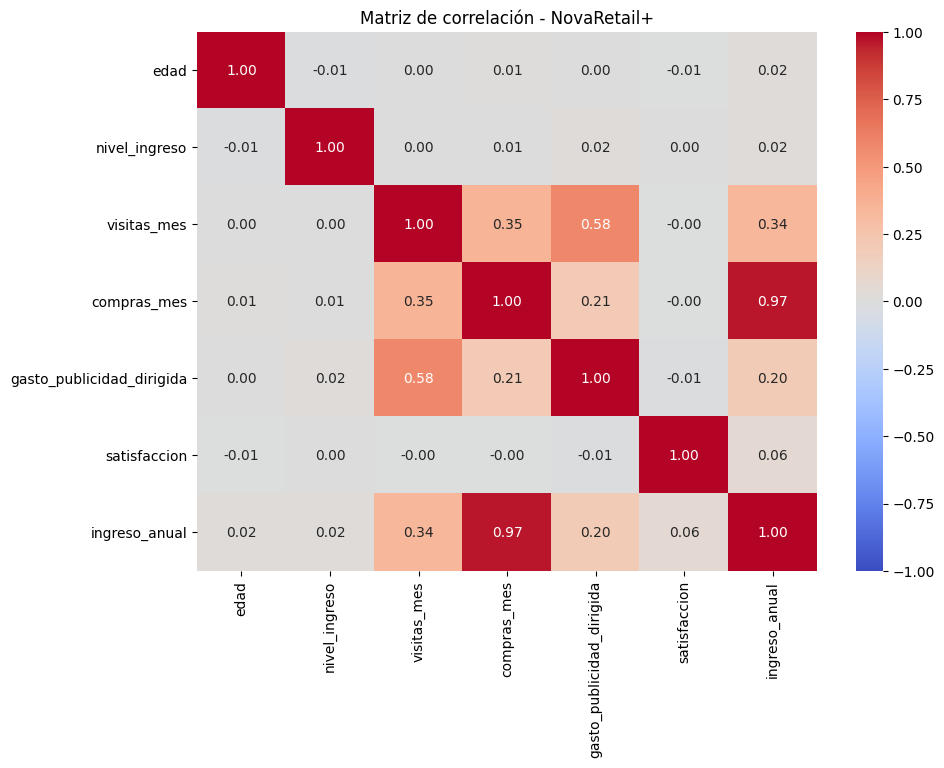

In [ ]:
# Visualizar la matriz de correlación para identificar relaciones
columnas_numericas = ['edad', 'nivel_ingreso', 'visitas_mes', 'compras_mes',
                      'gasto_publicidad_dirigida', 'satisfaccion', 'ingreso_anual']

corr = df[columnas_numericas].corr(method='pearson')

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Matriz de correlación - NovaRetail+")
plt.show()


✍️ **Comentario**:


Observaciones generales (Heatmap)  
- La correlación más alta es `compras_mes` con `ingreso_anual` (0.97), una relación fuerte.
- `visitas_mes` con `gasto_publicidad_dirigida` (0.58) es una relación moderada.
- Son relaciones débiles: `visitas_mes` con `compras_mes` (0.35), `visitas_mes` con `ingreso_anual` (0.34), `compras_mes` con `gasto_publicidad_dirigida` (0.21) y `gasto_publicidad_dirigida` con `ingreso_anual` (0.20).
- `edad`, `nivel_ingreso` y `satisfaccion` tienen una asociación prácticamente nula con las demás variables (valores entre -0.01 y 0.06; el valor más alto es `satisfaccion` con `ingreso_anual`, 0.06).
- No hay correlaciones negativas relevantes (el valor más bajo es -0.01).
- Ninguna pareja entre variables explicativas supera el umbral de colinealidad de 0.85; la única correlación mayor a 0.85 es `compras_mes` con `ingreso_anual`, que es la variable objetivo.

Observaciones respecto a `ingreso_anual`  
- Tiene una correlación fuerte con `compras_mes` (0.97). El 30.4% de los clientes tiene 0 compras e ingreso 0, pero al excluirlos la correlación sigue siendo alta (0.93); la relación no se debe solo a ese bloque, aunque en gran parte es esperable, porque cada compra genera ingreso.
- Tiene correlaciones débiles con `visitas_mes` (0.34) y con `gasto_publicidad_dirigida` (0.20).
- Tiene una asociación prácticamente nula con `satisfaccion` (0.06), `edad` (0.02) y `nivel_ingreso` (0.02); el ingreso estimado del cliente no se asocia con lo que genera para la empresa.


### Scatterplot general

Decisión: sí se incluye el scatterplot general.
Justificación: el heatmap solo resume la relación lineal con un número; el gráfico permite ver si la correlación de 0.97 entre compras e ingreso viene de una relación realmente lineal o de un bloque de clientes con 0 compras e ingreso 0.

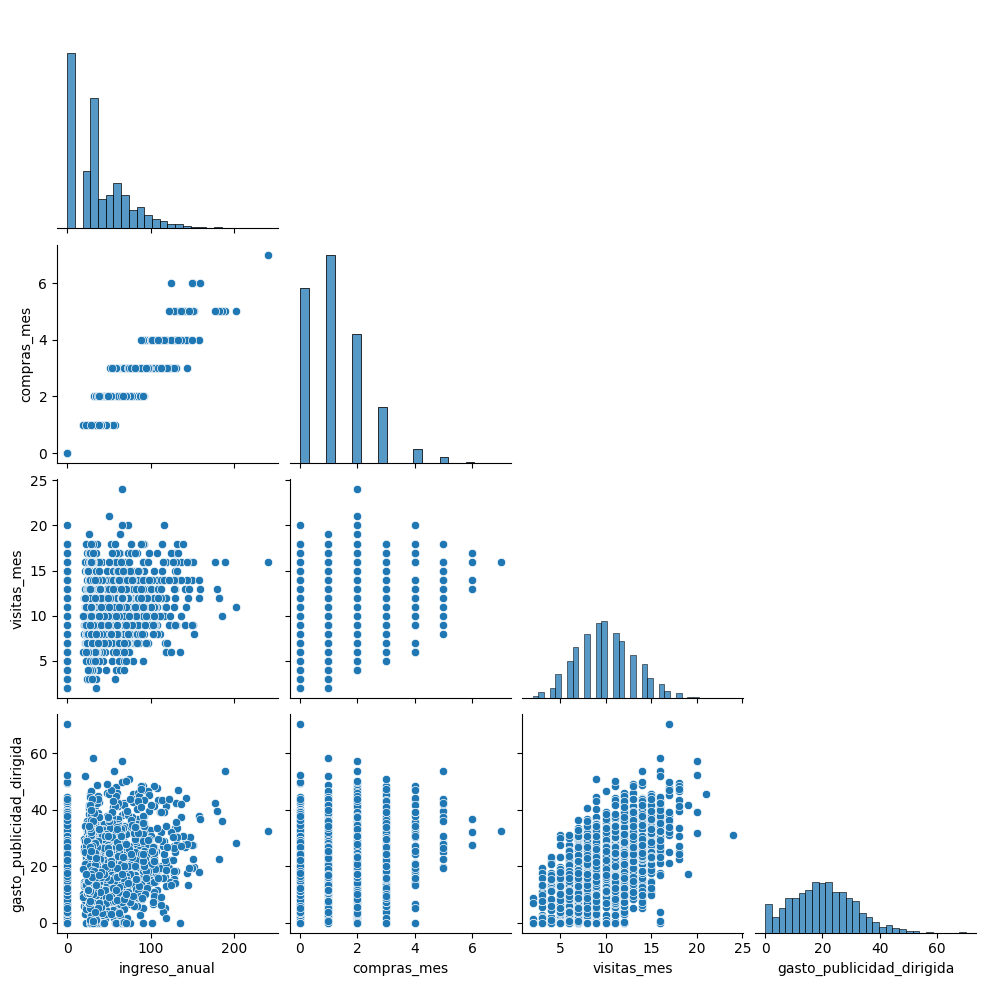

In [ ]:
# Scatterplot general de las variables más relacionadas con ingreso_anual
muestra = df.sample(2000, random_state=42)
sns.pairplot(muestra[['ingreso_anual', 'compras_mes', 'visitas_mes', 'gasto_publicidad_dirigida']], corner=True)
plt.show()

Patrones observados: `ingreso_anual` crece de forma escalonada con `compras_mes` (la variable es entera). Esa tendencia creciente se mantiene también entre los clientes que sí compraron, por lo que el 0.97 no proviene solo del bloque de clientes con 0 compras e ingreso 0 (coherente con el 0.93 sin ellos). Con `visitas_mes` y `gasto_publicidad_dirigida` se ven nubes dispersas, con una columna de clientes de ingreso 0 en x = 0 (en esta cuadrícula `ingreso_anual` está en el eje horizontal). Entre `visitas_mes` y `gasto_publicidad_dirigida` se observa un patrón ascendente claro. Nota: esta figura usa una muestra de 2,000 filas; los coeficientes 0.97 y 0.93 se calcularon con el conjunto de datos completo.

### Scatterplot para pares clave

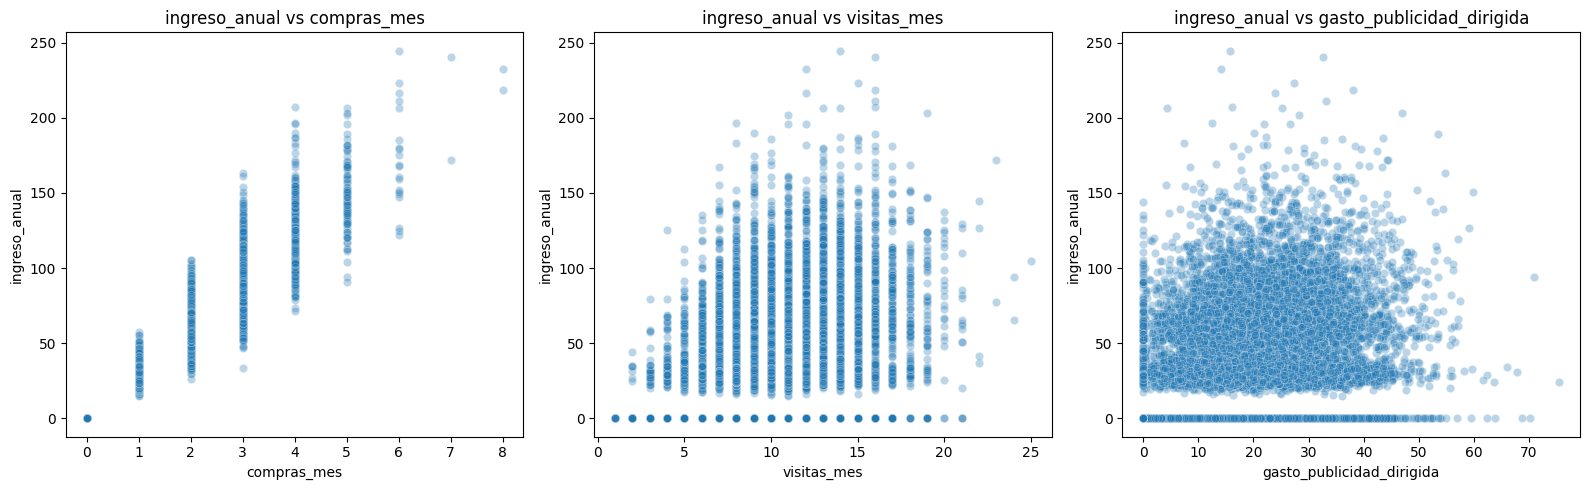

In [ ]:
# Visualizar pares de variables con relaciones moderadas o fuertes
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.scatterplot(data=df, x='compras_mes', y='ingreso_anual', alpha=0.3, ax=axes[0])
axes[0].set_title('ingreso_anual vs compras_mes')

sns.scatterplot(data=df, x='visitas_mes', y='ingreso_anual', alpha=0.3, ax=axes[1])
axes[1].set_title('ingreso_anual vs visitas_mes')

sns.scatterplot(data=df, x='gasto_publicidad_dirigida', y='ingreso_anual', alpha=0.3, ax=axes[2])
axes[2].set_title('ingreso_anual vs gasto_publicidad_dirigida')

plt.tight_layout()
plt.show()


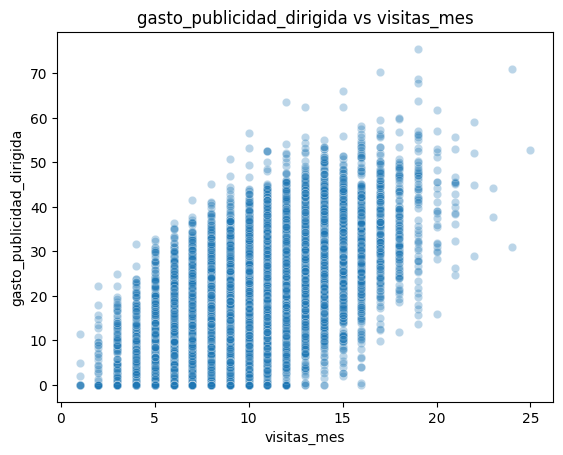

In [ ]:
sns.scatterplot(data=df, x='visitas_mes', y='gasto_publicidad_dirigida', alpha=0.3)
plt.title('gasto_publicidad_dirigida vs visitas_mes')
plt.show()

✍️ **Comentario**:

Observaciones iniciales (Scatterplot)

**ingreso_anual vs compras_mes**
- Dirección: positiva y casi lineal; a más compras en el mes, mayor ingreso anual. En 0 compras se ve un único punto, pero representa a los 4,567 clientes superpuestos con 0 compras e ingreso 0.
- Dispersión: baja en los niveles bajos de compras y creciente en los altos (por ejemplo, con 4 compras el ingreso va de unos 70 a 205), por lo que el ingreso por compra varía entre clientes.
- Outliers: pocos casos extremos con 6 a 8 compras e ingresos de 125 a 245; no alteran la tendencia general.
- Posible colinealidad: relación fuerte (0.97), pero `compras_mes` es una variable explicativa y `ingreso_anual` la variable objetivo, por lo que no es una redundancia entre predictores; el bloque de 4,567 clientes con 0 compras e ingreso 0 refuerza la relación, aunque sin ellos la correlación sigue siendo alta (0.93).

**ingreso_anual vs visitas_mes**
- Dirección: positiva y débil; el ingreso tiende a subir hasta unas 15 a 18 visitas y, a partir de ahí, los ingresos más altos disminuyen (forma de arco). Pocos clientes tienen tantas visitas, por lo que no conviene sobreinterpretar esta caída.
- Dispersión: alta; para cada número de visitas hay clientes con ingresos muy distintos, y aparece una fila de clientes con ingreso 0 en todos los niveles de visitas.
- Outliers: algunos clientes con ingresos superiores a 200 con 12 a 16 visitas, y clientes con muchas visitas (más de 20) e ingreso bajo.
- Posible colinealidad: no aplica; la relación es débil (0.34) y las visitas no bastan por sí solas para explicar el ingreso.

**ingreso_anual vs gasto_publicidad_dirigida**
- Dirección: positiva y débil (0.20).
- Dispersión: muy alta; la nube es muy densa y sin una forma clara, y también aparece la fila de ingreso 0 en todos los valores de gasto.
- Outliers: unos pocos clientes con gasto superior a 60 e ingreso bajo, y clientes con ingreso superior a 200 con gasto moderado.
- Posible colinealidad: no aplica; el gasto publicitario por usuario se asocia solo débilmente con el ingreso.

**gasto_publicidad_dirigida vs visitas_mes**
- Dirección: positiva y moderada (0.58); a más visitas, mayor gasto publicitario asignado.
- Dispersión: media y creciente (forma de abanico); la banda sube con las visitas, con mucha variación en cada nivel (por ejemplo, con 5 visitas el gasto va de 0 a unos 30).
- Outliers: pocos clientes con gasto cercano a 70 y casos con más de 20 visitas.
- Posible colinealidad: no supera el umbral de 0.85, por lo que no se consideran redundantes, aunque están relacionadas; es probable que el gasto se asigne más a quienes visitan más.

## Sección 4 - Coeficientes de correlación y evidencia numérica

En esta sección, se reportan coeficientes que respaldan los patrones
observados visualmente, utilizando el método adecuado según el tipo
de variables.

### Pearson / Spearman

In [ ]:
# Calcular correlación entre variables relevantes
columnas_relevantes = ['ingreso_anual', 'compras_mes', 'visitas_mes', 'gasto_publicidad_dirigida']

pearson = df[columnas_relevantes].corr(method='pearson').round(2)
print("Correlación Pearson")
print(pearson)


Correlación Pearson
                           ingreso_anual  compras_mes  visitas_mes  \
ingreso_anual                       1.00         0.97         0.34   
compras_mes                         0.97         1.00         0.35   
visitas_mes                         0.34         0.35         1.00   
gasto_publicidad_dirigida           0.20         0.21         0.58   

                           gasto_publicidad_dirigida  
ingreso_anual                                   0.20  
compras_mes                                     0.21  
visitas_mes                                     0.58  
gasto_publicidad_dirigida                       1.00  


In [ ]:
# Calcular correlación entre variables relevantes
spearman = df[columnas_relevantes].corr(method='spearman').round(2)
print("Correlación Spearman")
print(spearman)


Correlación Spearman
                           ingreso_anual  compras_mes  visitas_mes  \
ingreso_anual                       1.00         0.97         0.32   
compras_mes                         0.97         1.00         0.33   
visitas_mes                         0.32         0.33         1.00   
gasto_publicidad_dirigida           0.18         0.19         0.56   

                           gasto_publicidad_dirigida  
ingreso_anual                                   0.18  
compras_mes                                     0.19  
visitas_mes                                     0.56  
gasto_publicidad_dirigida                       1.00  


In [ ]:
compradores = df[df['compras_mes'] > 0]
print(compradores['compras_mes'].corr(compradores['ingreso_anual'], method='pearson'))

0.934130496629332


✍️ **Comentario**:


Observaciones de correlación

ingreso_anual vs compras_mes
- Correlación: Pearson 0.97 y Spearman 0.97; dirección positiva y magnitud fuerte, tanto lineal como monótona. Al excluir a los 4,567 clientes sin compras (ingreso 0), la correlación de Pearson sigue siendo muy alta (0.93), por lo que la relación no se debe solo al bloque de ceros.
- Colinealidad: supera el umbral de 0.85, pero es la relación entre una variable explicativa y la variable objetivo, no una redundancia entre predictores.

ingreso_anual vs visitas_mes
- Correlación: Pearson 0.34 y Spearman 0.32; dirección positiva y magnitud débil.
- Colinealidad: no existe; las visitas por sí solas explican poco del ingreso.

ingreso_anual vs gasto_publicidad_dirigida
- Correlación: Pearson 0.20 y Spearman 0.18; dirección positiva y magnitud débil.
- Colinealidad: el gasto publicitario por usuario se asocia solo débilmente con el ingreso (0.20 / 0.18).

compras_mes vs visitas_mes
- Correlación: Pearson 0.35 y Spearman 0.33; dirección positiva y magnitud débil.
- Colinealidad: no existe; quienes visitan más tienden a comprar un poco más.

visitas_mes vs gasto_publicidad_dirigida
- Correlación: Pearson 0.58 y Spearman 0.56; dirección positiva y magnitud moderada, la más alta entre variables explicativas.
- Colinealidad: no supera el umbral de 0.85, por lo que no son redundantes, aunque están relacionadas; es probable que el gasto publicitario se asigne más a quienes visitan más.

Comparación entre métodos
- Pearson y Spearman difieren en 0.02 o menos en todas las parejas, lo que indica que las relaciones son consistentes y que los valores extremos y el sesgo de `ingreso_anual` no distorsionan los resultados.

### Punto-biserial

In [ ]:
# Calcular correlación entre variables relevantes
columnas_binarias = ['miembro_premium', 'abandono']
columnas_numericas = ['ingreso_anual', 'compras_mes', 'visitas_mes',
                      'gasto_publicidad_dirigida', 'satisfaccion']

for col_bin in columnas_binarias:
    print(f"--- {col_bin} ---")
    for col_num in columnas_numericas:
        coef, p_value = pointbiserialr(df[col_bin], df[col_num])
        print(f"{col_bin} vs {col_num}: {coef:.3f}")
    print()


--- miembro_premium ---
miembro_premium vs ingreso_anual: 0.093
miembro_premium vs compras_mes: 0.003
miembro_premium vs visitas_mes: -0.013
miembro_premium vs gasto_publicidad_dirigida: 0.003
miembro_premium vs satisfaccion: 0.026

--- abandono ---
abandono vs ingreso_anual: -0.003
abandono vs compras_mes: 0.008
abandono vs visitas_mes: -0.009
abandono vs gasto_publicidad_dirigida: -0.005
abandono vs satisfaccion: -0.024



✍️ **Comentario**:

Observaciones Punto-biserial

miembro_premium vs ingreso_anual
- Asociación positiva y muy débil (0.093, menor a 0.1). En promedio, los clientes premium tienen un ingreso anual mayor (44.58 frente a 35.30), pero hay mucha variación dentro de cada grupo.
- Entre los clientes con compras, el ingreso anual dividido entre las compras mensuales es mayor en premium (36.67 frente a 29.35). Es una medida derivada que no equivale al valor real de cada compra, porque combina un ingreso anual con compras de un mes.

miembro_premium vs resto de variables
- Asociación prácticamente nula con compras_mes (0.003), visitas_mes (-0.013), gasto_publicidad_dirigida (0.003) y satisfaccion (0.026): los clientes premium y no premium tienen valores similares en estas variables.

abandono vs variables numéricas
- Asociación prácticamente nula con ingreso_anual (-0.003), compras_mes (0.008), visitas_mes (-0.009), gasto_publicidad_dirigida (-0.005) y satisfaccion (-0.024): los clientes que abandonan y los que permanecen tienen valores similares.

In [ ]:
print(df.groupby('miembro_premium')['ingreso_anual'].mean().round(2))

miembro_premium
0    35.30
1    44.58
Name: ingreso_anual, dtype: float64


In [ ]:
compradores = df[df['compras_mes'] > 0].copy()
compradores['ingreso_por_compra'] = compradores['ingreso_anual'] / compradores['compras_mes']
print(compradores.groupby('miembro_premium')['ingreso_por_compra'].mean().round(2))

miembro_premium
0    29.35
1    36.67
Name: ingreso_por_compra, dtype: float64


### V de Cramér

In [ ]:
# Función para calcular V de Cramér
def cramers_v(df, col_1, col_2):
    # tabla de contingencia
    tabla = pd.crosstab(df[col_1], df[col_2])

    # chi-cuadrado
    chi2, _, _, _ = chi2_contingency(tabla)

    # coeficiente V de Cramér
    n = tabla.values.sum()
    v = np.sqrt(chi2 / (n * (min(tabla.shape) - 1)))

    return v


In [ ]:
# Aplicar V de Cramér en variables relevantes
pares = [
    ('tipo_dispositivo', 'region'),
    ('tipo_dispositivo', 'miembro_premium'),
    ('tipo_dispositivo', 'abandono'),
    ('region', 'miembro_premium'),
    ('region', 'abandono'),
    ('miembro_premium', 'abandono')
]

for col_1, col_2 in pares:
    v = cramers_v(df, col_1, col_2)
    print(f"V de Cramér ({col_1} vs {col_2}): {v:.3f}")



V de Cramér (tipo_dispositivo vs region): 0.012
V de Cramér (tipo_dispositivo vs miembro_premium): 0.020
V de Cramér (tipo_dispositivo vs abandono): 0.007
V de Cramér (region vs miembro_premium): 0.013
V de Cramér (region vs abandono): 0.015
V de Cramér (miembro_premium vs abandono): 0.120


In [ ]:
print(pd.crosstab(df['miembro_premium'], df['abandono'], normalize='index').mul(100).round(1))

abandono            0     1
miembro_premium            
0                83.2  16.8
1                95.6   4.4


✍️ **Comentario**:

Observaciones V de Cramér

- tipo_dispositivo vs region (0.012), tipo_dispositivo vs miembro_premium (0.020), tipo_dispositivo vs abandono (0.007), region vs miembro_premium (0.013) y region vs abandono (0.015): asociación prácticamente nula (todas menores a 0.03). El dispositivo y la región prácticamente no se asocian con ser premium, con abandonar ni entre sí.
- miembro_premium vs abandono (0.120): es la única asociación que supera 0.1, de magnitud débil, pero con una diferencia relevante: los clientes premium abandonan menos (4.4% frente a 16.8% de los no premium, casi 4 veces menos).
- Ninguna asociación se acerca al umbral de colinealidad (0.85): salvo la asociación débil entre miembro_premium y abandono, no se observan asociaciones entre estas variables, por lo que no hay señal de redundancia.


## Sección 5 - Interpretación de resultados para el negocio

Cada hallazgo  debe incluir:
1) Evidencia visual (si aplica)
2) Evidencia numérica  
3) Interpretación (no causal)  
4) No podemos afirmar
5) Implicación de negocio

---

# Hallazgo 1 — Las compras mensuales son el factor más fuertemente asociado con el ingreso anual.

- Evidencia visual: el scatterplot de ingreso_anual vs compras_mes muestra una relación creciente casi lineal; el ingreso es 0 sin compras y sube con cada compra adicional. En el heatmap, esta es la celda más intensa de la fila de ingreso_anual.

- Evidencia numérica: correlación de 0.97 (Pearson y Spearman). Al excluir a los 4,567 clientes sin compras (30.4%), la correlación de Pearson sigue siendo alta (0.93).

- Interpretación: los clientes que compran más veces tienden a generar mucho más ingreso. La relación no depende solo del bloque de clientes con 0 compras e ingreso 0.

- No podemos afirmar: que aumentar las compras cause por sí solo un aumento proporcional del ingreso. Parte de la relación es esperada, porque cada compra genera ingreso, y la dispersión crece en los niveles altos de compras.

- Implicación de negocio: las acciones que incrementen las compras (conversión, recompra, ofertas) son las que más se asocian con el ingreso. Conviene enfocarse en los factores que llevan a comprar y no en la compra misma.  


# Hallazgo 2 — Premium se asocia con un ingreso algo mayor y un menor abandono

**Evidencia visual:** gráfico de barras con el ingreso anual promedio y la tasa de abandono según `miembro_premium`.

**Evidencia numérica:** ingreso anual promedio de 44.58 en premium frente a 35.30 en no premium. Entre los clientes con compras, el ingreso anual dividido entre las compras mensuales es de 36.67 frente a 29.35 (medida derivada: combina un ingreso anual con compras de un mes, por lo que no equivale al valor real de cada compra). La correlación punto-biserial con el ingreso es muy débil (0.093) y con las compras es prácticamente nula (0.003). La tasa de abandono es de 4.4% en premium frente a 16.8% en no premium (V de Cramér = 0.12, asociación débil).

**Interpretación:** los clientes premium muestran un ingreso algo mayor y menos abandono, sin diferencias en la cantidad de compras ni de visitas.

**No podemos afirmar:** que premium cause el mayor ingreso o el menor abandono. Pueden ser los clientes más comprometidos los que eligen premium, o quienes están por abandonar pueden cancelar primero su suscripción (causalidad inversa).

**Implicación de negocio:** premium es un segmento a observar de cerca. Conviene probar un piloto de conversión a premium con un grupo de control para medir si mejora la retención o solo la refleja.

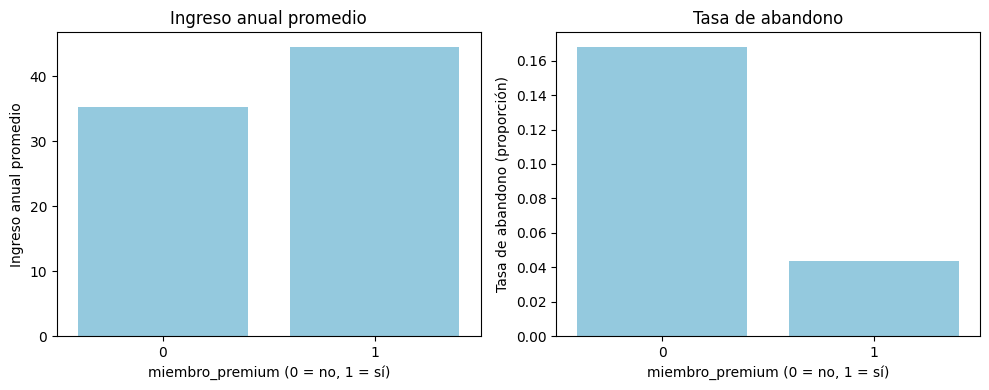

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.barplot(data=df, x='miembro_premium', y='ingreso_anual', ci=None, color='skyblue', ax=axes[0])
axes[0].set_title('Ingreso anual promedio')
axes[0].set_xlabel('miembro_premium (0 = no, 1 = sí)')
axes[0].set_ylabel('Ingreso anual promedio')

sns.barplot(data=df, x='miembro_premium', y='abandono', ci=None, color='skyblue', ax=axes[1])
axes[1].set_title('Tasa de abandono')
axes[1].set_xlabel('miembro_premium (0 = no, 1 = sí)')
axes[1].set_ylabel('Tasa de abandono (proporción)')

plt.tight_layout()
plt.show()

# Hallazgo 3 — Las visitas y la publicidad dirigida se asocian débilmente con el ingreso

**Evidencia visual:** en los scatterplots de `ingreso_anual` contra `visitas_mes` y contra `gasto_publicidad_dirigida` se ven nubes muy dispersas, con una fila de clientes de ingreso 0 en todos los valores del eje X. Entre visitas y gasto hay una tendencia creciente en forma de abanico.

**Evidencia numérica:** `ingreso_anual` vs `visitas_mes`, Pearson 0.34 y Spearman 0.32; `ingreso_anual` vs `gasto_publicidad_dirigida`, Pearson 0.20 y Spearman 0.18; `visitas_mes` vs `gasto_publicidad_dirigida`, 0.58 (moderada, sin llegar al umbral de colinealidad de 0.85). Además, `edad`, `nivel_ingreso` y `satisfaccion` casi no se asocian con el ingreso anual (0.02, 0.02 y 0.06).

**Interpretación:** más visitas se asocian con algo más de ingreso, y el gasto publicitario se asigna más a quienes visitan más, pero ninguna de las dos variables explica por sí sola el ingreso. Las características del cliente (edad, ingreso estimado y satisfacción) tampoco lo explican.

**No podemos afirmar:** que invertir más en publicidad dirigida aumente el ingreso. La relación es débil y puede deberse a que se asigna más gasto a clientes que ya son activos.

**Implicación de negocio:** conviene revisar la eficiencia del gasto publicitario por usuario y evaluarlo con un experimento antes de aumentarlo.

# Hallazgo 4 — El abandono no se distingue por las variables de comportamiento analizadas

**Evidencia visual:** no se generó un gráfico específico para este hallazgo.

**Evidencia numérica:** las correlaciones punto-biserial de `abandono` con ingreso, compras, visitas, gasto publicitario y satisfacción están entre -0.024 y 0.008. Tampoco hay asociación con el tipo de dispositivo (V = 0.007) ni con la región (V = 0.015).

**Interpretación:** con las variables analizadas, los clientes que abandonan son muy parecidos a los que permanecen; la única señal es una asociación modesta con la suscripción premium (V = 0.12, Hallazgo 2).

**No podemos afirmar:** que estas variables sean irrelevantes para el abandono en general, solo que no lo distinguen en este análisis (`edad` y `nivel_ingreso` no se contrastaron con `abandono`).

**Implicación de negocio:** para entender y anticipar el abandono hacen falta otros datos, como precio, antigüedad del cliente, motivo de baja o experiencia de servicio.

# Sección 6 - Limitaciones y próximos pasos

# 6.1. Limitaciones

- **Correlación ≠ causalidad:** los coeficientes muestran que las variables se mueven juntas, no que una cause a la otra.
- **Relación casi mecánica entre compras e ingreso:** es probable que `ingreso_anual` dependa directamente de las compras, por lo que la correlación de 0.97 entre ambas es en parte esperada y poco informativa por sí sola.
- **Bloque de clientes sin compras:** el 30.4% de los clientes (4,567) tiene 0 compras e ingreso 0, lo que influye en las correlaciones; al excluirlos, la relación se mantiene (0.93), pero el resto de las variables se mide con ese bloque incluido.
- **Periodo único:** los datos cubren solo 2024 (corte transversal), por lo que no se pueden observar tendencias ni cambios en el tiempo.
- **Variables limitadas:** el dataset no incluye precio, tipo de producto, antigüedad del cliente ni el motivo de baja, factores que podrían explicar el ingreso y el abandono.
- **Autoselección en premium:** los clientes eligen ser premium, por lo que su menor abandono y mayor ingreso pueden deberse a que ya eran clientes más comprometidos.
- **Análisis de a pares:** cada correlación se calculó entre dos variables a la vez, sin controlar por las demás; la V de Cramér además no indica la dirección de la asociación.
- **Sin pruebas de significancia:** no se evaluó la significancia estadística de los coeficientes.

# 6.2. Próximos pasos

**Paso 1: Probar segmentación adicional**

- Comparar el ingreso, las compras y el abandono por grupos (premium vs no premium, clientes con y sin compras, niveles de compras).
- Analizar si las relaciones cambian por región y tipo de dispositivo.

**Paso 2: Profundizar en el abandono**

- Incorporar variables nuevas (antigüedad, precio pagado, tickets de soporte, motivo de baja).
- Construir un modelo que combine varias variables a la vez para identificar qué clientes tienen mayor riesgo de abandonar.

**Paso 3: Validar con experimentos**

- Realizar un piloto de conversión a premium con grupo de control para medir su efecto real en la retención y en el ingreso.
- Probar variaciones en el gasto en publicidad dirigida (A/B) antes de aumentar la inversión.

**Paso 4: Análisis multivariado**

- Usar una regresión para estimar el efecto de cada variable sobre el ingreso anual controlando por las demás.